In [30]:
import pandas as pd
import matplotlib.pyplot as plt

In [31]:
df = pd.read_json('data/tumor_instance_data.json')
df['tumor_to_scan_z_axis'] = df['tumor_z'] / df['scan_z_axis']
df.describe()

,scan_z_axis,tumor_z,tumor_x,tumor_y,bounding_cube_volume,tumor_to_scan_z_axis
count,227.000000,227.000000,227.000000,227.000000,2.270000e+02,227.000000
mean,198.198238,27.189427,68.101322,67.220264,2.643681e+05,0.152897
std,191.613157,33.772197,42.799423,40.438470,7.639381e+05,0.110780
min,29.000000,3.000000,16.000000,15.000000,1.173000e+03,0.025253
25%,86.000000,8.000000,35.000000,36.000000,1.478100e+04,0.076807
50%,106.000000,15.000000,56.000000,55.000000,5.184000e+04,0.118280
75%,209.500000,28.500000,90.500000,85.000000,2.216170e+05,0.200000
max,834.000000,224.000000,242.000000,208.000000,8.517600e+06,0.666667


(array([ 7., 14., 18., 17., 23., 15., 18., 10.,  3., 15., 12.,  8.,  4.,
        10.,  8.,  5.,  5.,  4.,  4.,  2.,  3.,  0.,  3.,  2.,  1.,  2.,
         2.,  1.,  0.,  3.,  2.,  0.,  1.,  0.,  0.,  1.,  0.,  1.,  0.,
         0.,  0.,  0.,  0.,  0.,  1.,  0.,  1.,  0.,  0.,  1.]),
 array([0.02525253, 0.03808081, 0.05090909, 0.06373737, 0.07656566,
        0.08939394, 0.10222222, 0.11505051, 0.12787879, 0.14070707,
        0.15353535, 0.16636364, 0.17919192, 0.1920202 , 0.20484848,
        0.21767677, 0.23050505, 0.24333333, 0.25616162, 0.2689899 ,
        0.28181818, 0.29464646, 0.30747475, 0.32030303, 0.33313131,
        0.3459596 , 0.35878788, 0.37161616, 0.38444444, 0.39727273,
        0.41010101, 0.42292929, 0.43575758, 0.44858586, 0.46141414,
        0.47424242, 0.48707071, 0.49989899, 0.51272727, 0.52555556,
        0.53838384, 0.55121212, 0.5640404 , 0.57686869, 0.58969697,
        0.60252525, 0.61535354, 0.62818182, 0.6410101 , 0.65383838,
        0.66666667]),
 <BarContainer

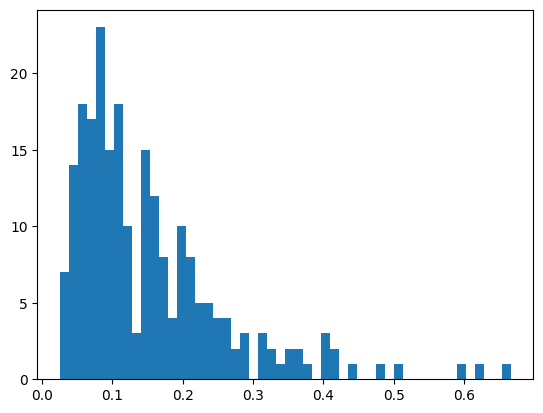

In [32]:
plt.hist(df['tumor_to_scan_z_axis'], bins=50)

In [33]:
print(df.count())
print(df[df['tumor_to_scan_z_axis'] < 0.4].count())
print(df[df['tumor_to_scan_z_axis'] < 0.4].count() / df.count())
print("we can reject all the tumors that are over 0.4 of the Z-height and will still have over 95% of the samples")

case_id                 227
scan_z_axis             227
tumor_z                 227
tumor_x                 227
tumor_y                 227
bounding_cube_volume    227
tumor_to_scan_z_axis    227
dtype: int64
case_id                 217
scan_z_axis             217
tumor_z                 217
tumor_x                 217
tumor_y                 217
bounding_cube_volume    217
tumor_to_scan_z_axis    217
dtype: int64
case_id                 0.955947
scan_z_axis             0.955947
tumor_z                 0.955947
tumor_x                 0.955947
tumor_y                 0.955947
bounding_cube_volume    0.955947
tumor_to_scan_z_axis    0.955947
dtype: float64
we can reject all the tumors that are over 0.4 of the Z-height and will still have over 95% of the samples


In [34]:
from modules import data_preprocessing
df = pd.read_csv('/home/marcel/Repos/Data/kits23_processed/labels.csv')
data_preprocessing.compute_radius_from_diameter(df)
print(df[['case_id', 'radius_annotation', 'computed_radius_points', 'calculated_diameter_mm']])

        case_id  radius_annotation  computed_radius_points  \
0    case_00000                0.0                       1   
1    case_00003                1.0                       1   
2    case_00004                1.0                       1   
3    case_00005                2.0                       2   
4    case_00007                1.0                       1   
..          ...                ...                     ...   
215  case_00581                0.0                       0   
216  case_00582                2.0                       2   
217  case_00583                2.0                       2   
218  case_00585                0.0                       0   
219  case_00588                1.0                       1   

     calculated_diameter_mm  
0                     31.14  
1                     32.51  
2                     42.60  
3                     61.69  
4                     38.97  
..                      ...  
215                   24.16  
216            

In [35]:
# 1. Create a filter for rows where both exist but are different
# We check .notna() to ignore cases where the doctor didn't provide a radius
mismatch_mask = (
    df['radius_annotation'].notna() & 
    (df['radius_annotation'] != df['computed_radius_points'])
)

# 2. Extract the mismatched rows
mismatches = df[mismatch_mask]

# 3. Print or Display
if mismatches.empty:
    print("All annotated cases match the computed points!")
else:
    print(f"Found {len(mismatches)} mismatches:")
    # Using display() for nice Jupyter formatting
    display(mismatches[['case_id', 'radius_annotation', 'computed_radius_points', 'calculated_diameter_mm']])

Found 48 mismatches:


,case_id,radius_annotation,computed_radius_points,calculated_diameter_mm
0,case_00000,0.0,1,31.14
10,case_00014,0.0,1,31.59
11,case_00016,1.0,2,53.97
16,case_00023,1.0,0,24.91
21,case_00033,0.0,1,28.06
25,case_00039,0.0,1,25.85
26,case_00040,0.0,1,29.74
32,case_00048,1.0,2,51.06
33,case_00049,0.0,1,28.61
41,case_00062,0.0,1,28.12
